Données : (251, 1) 2025-11-17 → 2026-11-16
Apprentissage : 2025-12-16 → 2026-08-07 (161 jours)
Test          : 2026-08-10 → 2026-11-16 (70 jours)
Jours signalés IF : 2 | 3σ : 1 sur 70


,rendement,vol_20,score
date,,,
2026-11-05,-4.453365,1.273477,0.076156
2026-11-09,2.319154,1.392788,0.009455


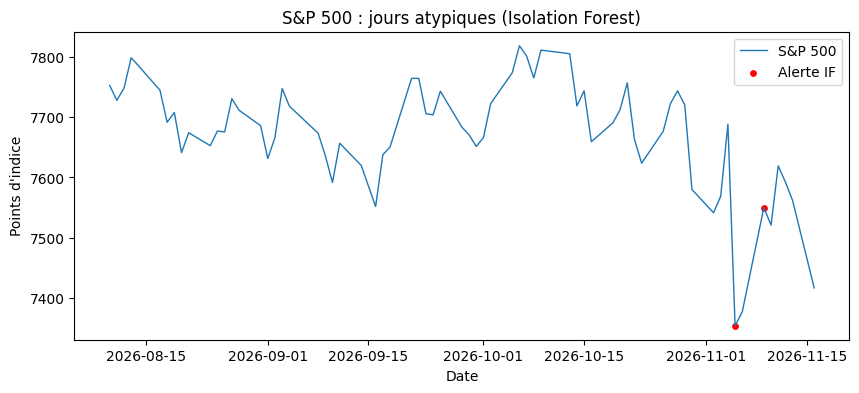

In [21]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42

def charger(url):
    d = pd.read_csv(url)
    d.columns = ["date", "SP500"]
    d["date"] = pd.to_datetime(d["date"])
    d["SP500"] = pd.to_numeric(d["SP500"], errors="coerce")
    return d.dropna().set_index("date")

urls = [
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2000-01-01&coed=2026-12-31",
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500",
]
df = None
for u in urls:
    try:
        d = charger(u)
        if df is None or len(d) > len(df):
            df = d
    except Exception as e:
        print("URL échouée :", e)
print("Données :", df.shape, df.index.min().date(), "→", df.index.max().date())

# Variables (passé uniquement)
df["rendement"] = np.log(df["SP500"]).diff() * 100
df["vol_20"]    = df["rendement"].rolling(20).std()
df["rend_5"]    = df["rendement"].rolling(5).sum()
df["drawdown"]  = (df["SP500"] / df["SP500"].cummax() - 1) * 100
df = df.dropna()

# Découpage chronologique automatique : 70 % apprentissage / 30 % test
X = ["rendement", "vol_20", "rend_5", "drawdown"]
coupure = int(len(df) * 0.7)
ent, test = df.iloc[:coupure].copy(), df.iloc[coupure:].copy()
print("Apprentissage :", ent.index.min().date(), "→", ent.index.max().date(), f"({len(ent)} jours)")
print("Test          :", test.index.min().date(), "→", test.index.max().date(), f"({len(test)} jours)")

# Référence : règle des 3 écarts-types
mu, sd = ent["rendement"].mean(), ent["rendement"].std()
test["alerte_3s"] = (test["rendement"] - mu).abs() / sd > 3

# Isolation Forest
modele = make_pipeline(
    StandardScaler(),
    IsolationForest(n_estimators=150, contamination=0.02, random_state=GRAINE)
).fit(ent[X])
test["alerte_if"] = modele.predict(test[X]) == -1
test["score"] = -modele.decision_function(test[X])

print("Jours signalés IF :", int(test["alerte_if"].sum()), "| 3σ :", int(test["alerte_3s"].sum()), "sur", len(test))
display(test[test["alerte_if"]].sort_values("score", ascending=False).head(10)[["rendement", "vol_20", "score"]])

plt.figure(figsize=(10, 4))
plt.plot(test.index, test["SP500"], lw=1, label="S&P 500")
plt.scatter(test.index[test["alerte_if"]], test["SP500"][test["alerte_if"]], c="red", s=15, label="Alerte IF")
plt.title("S&P 500 : jours atypiques (Isolation Forest)")
plt.xlabel("Date"); plt.ylabel("Points d'indice")
plt.legend(); plt.show()

In [22]:
brut = pd.read_csv(urls[0]); brut.columns = ["date", "SP500"]
brut["SP500"] = pd.to_numeric(brut["SP500"], errors="coerce")
print("Observations brutes :", len(brut), "| manquantes :", int(brut["SP500"].isna().sum()),
      f"({brut['SP500'].isna().mean()*100:.2f} %)")
print("Période :", brut["date"].iloc[0], "→", brut["date"].iloc[-1], "| fréquence : quotidienne")
display(df[["SP500"] + X].describe().round(2))

Observations brutes : 261 | manquantes : 10 (3.83 %)
Période : 2025-11-17 → 2026-11-16 | fréquence : quotidienne


,SP500,rendement,vol_20,rend_5,drawdown
count,231.00,231.00,231.00,231.00,231.00
mean,7283.78,0.04,0.80,0.21,-1.67
std,386.71,0.88,0.21,1.72,1.69
min,6343.72,-4.45,0.46,-4.87,-9.10
25%,6919.37,-0.42,0.65,-0.99,-2.32
50%,7408.50,0.02,0.74,0.09,-1.31
75%,7627.58,0.59,0.89,1.20,-0.38
max,7818.93,2.87,1.45,5.42,0.00


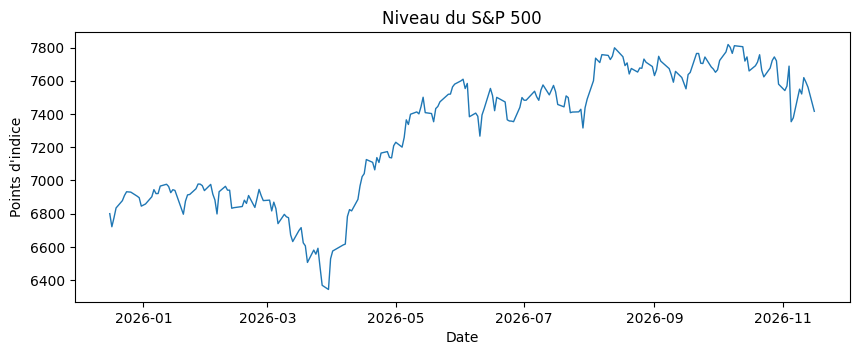

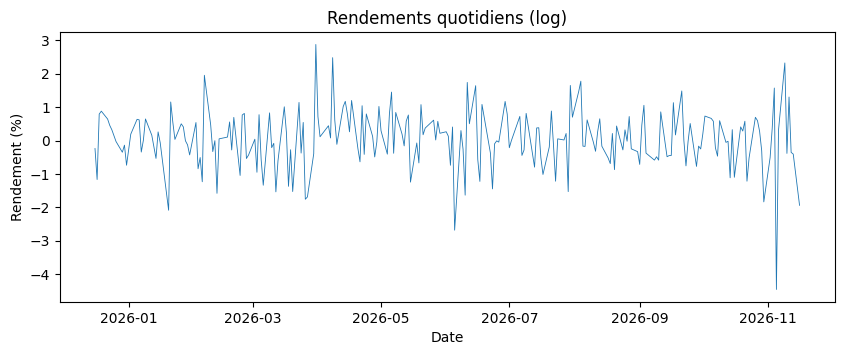

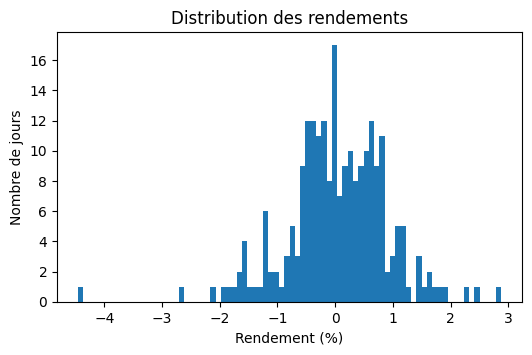

Kurtosis (excès) : 3.1 | asymétrie : -0.55
Doublons d'index : 0


In [23]:
import os; os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(10, 3.5)); plt.plot(df.index, df["SP500"], lw=1)
plt.title("Niveau du S&P 500"); plt.xlabel("Date"); plt.ylabel("Points d'indice")
plt.savefig("figures/g1_niveau.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(10, 3.5)); plt.plot(df.index, df["rendement"], lw=.6)
plt.title("Rendements quotidiens (log)"); plt.xlabel("Date"); plt.ylabel("Rendement (%)")
plt.savefig("figures/g2_rendements.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(6, 3.5)); plt.hist(df["rendement"], bins=80)
plt.title("Distribution des rendements"); plt.xlabel("Rendement (%)"); plt.ylabel("Nombre de jours")
plt.savefig("figures/g3_histogramme.png", dpi=150, bbox_inches="tight"); plt.show()

print("Kurtosis (excès) :", round(df["rendement"].kurt(), 2), "| asymétrie :", round(df["rendement"].skew(), 2))
print("Doublons d'index :", int(df.index.duplicated().sum()))

In [24]:
assert df.index.is_monotonic_increasing and ent.index.max() < test.index.min()
display(df[["SP500", "rendement", "vol_20", "rend_5", "drawdown"]].head(5).round(3))
print("Fin apprentissage :", ent.index.max().date(), "< début test :", test.index.min().date())
os.makedirs("data/processed", exist_ok=True)
df.to_csv("data/processed/sp500_variables.csv")

,SP500,rendement,vol_20,rend_5,drawdown
date,,,,,
2025-12-16,6800.26,-0.239,0.737,-0.590,-1.460
2025-12-17,6721.43,-1.166,0.763,-2.429,-2.602
2025-12-18,6774.76,0.790,0.777,-1.846,-1.829
2025-12-19,6834.50,0.878,0.688,0.104,-0.964
2025-12-22,6878.49,0.642,0.673,0.905,-0.326


Fin apprentissage : 2026-08-07 < début test : 2026-08-10


Événements dans la validation : 0


,contamination,jours signalés (%),événements retrouvés (%)
0,0.01,0.0,NaN
1,0.02,0.0,NaN
2,0.03,0.0,NaN
3,0.05,0.0,NaN


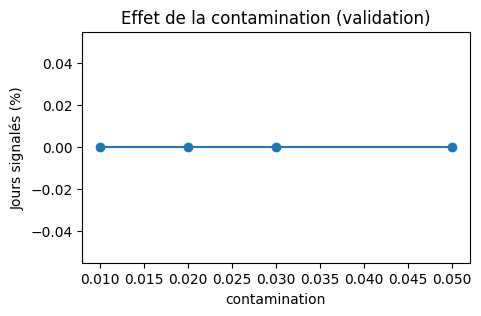

In [25]:
ev_dates = pd.to_datetime(["2018-02-05", "2018-12-24", "2020-03-09", "2020-03-12", "2020-03-16",
                           "2022-06-13", "2022-09-13", "2024-08-05", "2025-04-03", "2025-04-04", "2025-04-09"])

cut_val = int(len(ent) * 0.8)
ent_a, val = ent.iloc[:cut_val], ent.iloc[cut_val:]
ev_val = ev_dates[ev_dates.isin(val.index)]
print("Événements dans la validation :", len(ev_val))

lignes = []
for c in [0.01, 0.02, 0.03, 0.05]:
    m = make_pipeline(StandardScaler(), IsolationForest(n_estimators=150, contamination=c, random_state=GRAINE)).fit(ent_a[X])
    a = pd.Series(m.predict(val[X]) == -1, index=val.index)
    lignes.append((c, a.mean() * 100, a.loc[ev_val].mean() * 100 if len(ev_val) else np.nan))
tab = pd.DataFrame(lignes, columns=["contamination", "jours signalés (%)", "événements retrouvés (%)"]).round(2)
display(tab)

plt.figure(figsize=(5, 3)); plt.plot(tab["contamination"], tab["jours signalés (%)"], marker="o")
plt.title("Effet de la contamination (validation)"); plt.xlabel("contamination"); plt.ylabel("Jours signalés (%)")
plt.savefig("figures/g4_contamination.png", dpi=150, bbox_inches="tight"); plt.show()

,Méthode,Jours signalés (%),Événements retrouvés (sur 0)
0,Règle 3σ (référence),1.43,0
1,Isolation Forest,2.86,0


Alertes IF sur apprentissage : 2.48 % | test : 2.86 %
Graine 1 : 2/2 alertes communes avec la graine 42
Graine 7 : 2/2 alertes communes avec la graine 42
Graine 2024 : 2/2 alertes communes avec la graine 42
Graine 99 : 2/2 alertes communes avec la graine 42


,SP500,rendement,vol_20,score,alerte_if,alerte_3s,evenement_documente
date,,,,,,,
2026-11-05,7353.73,-4.453,1.273,0.076,True,True,False
2026-11-09,7549.94,2.319,1.393,0.009,True,False,False
2026-11-16,7416.59,-1.937,1.450,-0.009,False,False,False
2026-11-06,7376.86,0.314,1.265,-0.023,False,False,False
2026-11-12,7592.40,-0.355,1.411,-0.035,False,False,False


Événements manqués par IF : []
Alertes IF sans événement documenté : 2


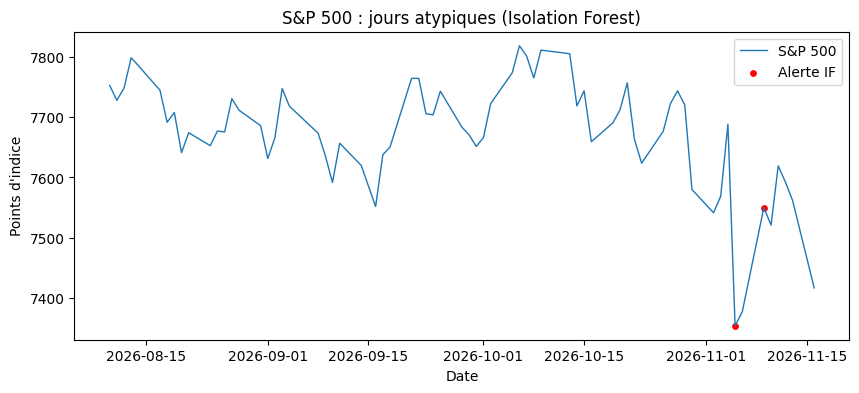

In [26]:
c_final = 0.02   # à choisir d'après le tableau de validation ci-dessus

modele = make_pipeline(StandardScaler(), IsolationForest(n_estimators=150, contamination=c_final, random_state=GRAINE)).fit(ent[X])
test["alerte_if"] = modele.predict(test[X]) == -1
test["score"] = -modele.decision_function(test[X])
test["alerte_3s"] = (test["rendement"] - mu).abs() / sd > 3

ev_test = ev_dates[ev_dates.isin(test.index)]
res = pd.DataFrame({
    "Méthode": ["Règle 3σ (référence)", "Isolation Forest"],
    "Jours signalés (%)": [test["alerte_3s"].mean() * 100, test["alerte_if"].mean() * 100],
    f"Événements retrouvés (sur {len(ev_test)})": [test.loc[ev_test, "alerte_3s"].sum(), test.loc[ev_test, "alerte_if"].sum()],
}).round(2)
display(res)

# Surapprentissage : taux d'alertes sur l'apprentissage vs test
print("Alertes IF sur apprentissage :", round((modele.predict(ent[X]) == -1).mean() * 100, 2), "% | test :", round(test["alerte_if"].mean() * 100, 2), "%")

# Stabilité selon la graine
ref = set(test.index[test["alerte_if"]])
for s in [1, 7, 2024, 99]:
    m = make_pipeline(StandardScaler(), IsolationForest(n_estimators=150, contamination=c_final, random_state=s)).fit(ent[X])
    ens = set(test.index[m.predict(test[X]) == -1])
    print(f"Graine {s} : {len(ens & ref)}/{len(ref)} alertes communes avec la graine {GRAINE}")

# Illustration : 5 jours du test avec leur score
test["evenement_documente"] = test.index.isin(ev_dates)
display(test.sort_values("score", ascending=False).head(5)[["SP500", "rendement", "vol_20", "score", "alerte_if", "alerte_3s", "evenement_documente"]].round(3))

# Analyse des erreurs : événements manqués et alertes sans événement documenté
print("Événements manqués par IF :", [d.date() for d in ev_test if not test.loc[d, "alerte_if"]])
print("Alertes IF sans événement documenté :", int((test["alerte_if"] & ~test["evenement_documente"]).sum()))

plt.figure(figsize=(10, 4)); plt.plot(test.index, test["SP500"], lw=1, label="S&P 500")
plt.scatter(test.index[test["alerte_if"]], test["SP500"][test["alerte_if"]], c="red", s=15, label="Alerte IF")
plt.title("S&P 500 : jours atypiques (Isolation Forest)"); plt.xlabel("Date"); plt.ylabel("Points d'indice")
plt.legend(); plt.savefig("figures/g5_alertes.png", dpi=150, bbox_inches="tight"); plt.show()

In [27]:
import sklearn, matplotlib, sys
open("requirements.txt", "w").write(
    f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nmatplotlib=={matplotlib.__version__}\n")
print("Python", sys.version.split()[0]); print(open("requirements.txt").read())

Python 3.13.18
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0



In [28]:
import os
for d in ["data/raw", "data/processed", "docs", "notebooks", "src", "figures", "rapport", "presentation"]:
    os.makedirs(d, exist_ok=True)
open(".gitignore", "w").write(".ipynb_checkpoints/\n__pycache__/\n*.pyc\n.env\n.DS_Store\n")

54

In [33]:
!git clone https://github.com/ouhaddidoha-encg/CC-partieB-25009275-DohaOuhaddi-FIN3
%cd CodeApogee-Nom-Groupe

# Commit 1 : après la section 2 (données)
!git add .
!git commit -m "Commit 1 : description des donnees"
!git push

# Commit 2 : après la section 7 (modélisation)
!git add .
!git commit -m "Commit 2 : modelisation et resultats"
!git push

# Commit final, étiqueté
!git add .
!git commit -m "Remise finale"
!git tag remise-finale
!git push
!git push origin remise-finale

fatal: destination path 'CC-partieB-25009275-DohaOuhaddi-FIN3' already exists and is not an empty directory.
[Errno 2] No such file or directory: 'CodeApogee-Nom-Groupe'
/content
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [43]:
# F7 – Détection d'anomalies sur le S&P 500
**Auteur :** Ouhaddi Doha – Code Apogée [25007592] – Groupe [3]
**Résumé :** détection de séances de bourse atypiques sur le S&P 500 avec un Isolation Forest, comparé à la règle des trois écarts-types.

## Problématique et résultats
L'Isolation Forest repère-t-il mieux les séances de stress documentées que la règle |z| > 3 ?

| Méthode | Jours signalés (%) | Événements retrouvés |
|---|---|---|
| Règle 3σ | [..] | [../..] |
| Isolation Forest | [..] | [../..] |

## Données
FRED, série SP500 : https://fred.stlouisfed.org/series/SP500 – extraction du [jj/mm/2026] – licence : [..].

## Installation
Python [3.x] : `pip install -r requirements.txt`

## Exécution
Ouvrir `notebooks/projet_F7.ipynb`, puis « Redémarrer et tout exécuter » (environ [..] min).

## Structure
data/ · docs/ · notebooks/ · figures/ · rapport/ · presentation/

## Références
Voir `docs/references.md` et `DECLARATION_IA.md`.

SyntaxError: invalid character '–' (U+2013) (3078923947.py, line 2)

In [45]:
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Claude (Anthropic) | 17/11/2026 | [explication d'une erreur, suggestion de code] | [Notebook, sections ..] | [code lu, testé, sorties vérifiées] |

SyntaxError: unterminated string literal (detected at line 3) (2000984387.py, line 3)

### Configuration de l'identité et de l'authentification Git
Pour pouvoir pousser vos commits vers votre dépôt GitHub privé sans blocage, nous allons utiliser le gestionnaire de secrets de Colab pour récupérer de façon sécurisée votre jeton d'accès personnel GitHub (Personal Access Token - PAT).

In [44]:
from google.colab import userdata
import os

# 1. Configuration de l'identité Git globale
USER_EMAIL = "ouhaddi.doha6747.encg@uhp.ac.ma"  # À remplacer par votre e-mail GitHub
USER_NAME = "ouhaddidoha"                 # À remplacer par votre nom d'utilisateur GitHub

!git config --global user.email "{USER_EMAIL}"
!git config --global user.name "{USER_NAME}"
print("✓ Identité Git configurée avec succès.")

# 2. Récupération sécurisée du token d'accès GitHub (PAT)
# Assurez-vous d'avoir créé un secret nommé 'GITHUB_TOKEN' dans l'onglet "🔑" à gauche de Colab
try:
    token = userdata.get('GITHUB_TOKEN')
    repo_url = f"https://{token}@github.com/ouhaddidoha-encg/CC-partieB-25009275-DohaOuhaddi-FIN3.git"
    os.environ["REPO_URL"] = repo_url
    print("✓ Token récupéré. Prêt pour l'authentification du dépôt.")
except Exception as e:
    print("⚠ Erreur : Le secret 'GITHUB_TOKEN' n'a pas pu être récupéré dans les secrets de Colab.", e)

✓ Identité Git configurée avec succès.
⚠ Erreur : Le secret 'GITHUB_TOKEN' n'a pas pu être récupéré dans les secrets de Colab. Secret GITHUB_TOKEN does not exist.
